# 99 Build the planner on the real data

The demand-flexibility and battery planner (`web/part3/`) is a single web page that opens straight in a
browser, with no server. It doesn't read the database while it runs: its data are built into the page. This notebook
does that build, on the results of the earlier notebooks:

1. **Export** (`scripts/export_part3_inputs.py`): the hourly loads and one row per customer (segment, programme
   flags, appliance types and confidences, technology scores, list flags, mid-year change flags) from `avangrid.db`
   and the cached arrays, to `onedrive-export/Data/part3/`.
2. **Build, once per utility** (`scripts/run_part3.py --utility ...`): the planner's calculations (system peak,
   flexible loads, battery sizing, customer economics, ranking) with the assumptions in
   `config/part3_assumptions.json`, but priced on that utility's real residential time-varying rate from
   `data/tariffs/residential_tariffs.json` (scripts/fetch_tariffs.py). Each utility gets its own page.
3. **A starting page** with a drop-down to switch between the four utilities' planners.

**Batteries are dispatched as one fleet** (`fleet` in the config). The planner's per-home simulation picks which homes
could take a battery and how big; then, instead of every battery charging in the same hours (which created a new
overnight peak), a daily linear program sets the whole fleet's charging and discharging to minimize the system peak,
and the fleet size is the knee of the peak-versus-fleet-size curve: the smallest fleet within 5% of the best
achievable peak. Section 3 sets out the rules and the optimization, and shows the curve and which homes make the cut.

Prices change bill savings, payback and NPV, and through them each home's economics score, rank and programme
channel, so every utility needs its own build; battery sizing and the peak reduction don't depend on prices and are
the same in all four. The meter data come from one service area (the challenge documents don't say which), so the
four pages answer "what if these homes were on this utility's rate".

At the end, open **`onedrive-export/Data/part3/index.html`** in a browser (the last cell prints a link). Each page
lists the top 3,000 customers individually (set `MAX_CUSTOMERS` in the setup cell to change that); its summary
figures cover everyone.

**The page holds real customer data.** It is written inside the git-ignored data folder; don't commit it or share it
outside the event. The committed `web/part3/index.html` uses a synthetic demonstration dataset and is safe to share.

Run after notebooks 10–70 (the export needs `technology_predictions`, `appliance_inventory`, `customer_segments` and
`change_points`). How each step works is described in `web/part3/README.md` and on the page's Methodology tab.

## Setup

In [1]:
import json
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from avangrid import config

ROOT = Path.cwd()
PART3 = config.DATA_DIR / 'part3'
# Utilities to build, in drop-down order (the first is the default), and the rate each one uses (see data/tariffs/README.md).
UTILITIES = {'nyseg': 'NYSEG (West): Day/Night (SC 8)', 'cmp': 'CMP: Time-of-use (A-TOU)',
             'rge': 'RG&E: Time-of-use (SC 4)', 'ui': 'UI: Time-of-use (RT)'}
# Customers listed individually on the page (the top-ranked ones). Every summary figure still covers all customers.
# 3,000 gives a page of about 30 MB that opens quickly; 0 lists everyone (about 160 MB, slow to open).
MAX_CUSTOMERS = 3000


def run(script, *args):
    """Run a project script with this notebook's Python, show its output, and stop the notebook if it fails."""
    t = time.time()
    r = subprocess.run([sys.executable, str(ROOT / 'scripts' / script), *map(str, args)], cwd=ROOT,
                       capture_output=True, text=True)
    print(r.stdout[-4000:] + (('\n' + r.stderr[-4000:]) if r.returncode else ''))
    if r.returncode:
        raise RuntimeError(f'{script} failed (exit code {r.returncode})')
    print(f'{script}: done in {time.time() - t:.0f}s')

## 1. Export the inputs from the database

In [2]:
run('export_part3_inputs.py')
manifest = json.loads((PART3 / 'manifest.json').read_text())
{k: v for k, v in manifest.items() if not isinstance(v, (dict, list))}

Loading hourly arrays (cached)...
Filling gaps for 33,310 customers x 365 days...
Joining customer appliance classification and customer segmentation results...
Wrote 33,310 customers x 8,760 hours to /Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/part3
  hourly_kwh.npy 1.17 GB, customers.csv 61 columns

export_part3_inputs.py: done in 9s


{'generated': '2026-11-14T08:28:35',
 'source': 'avangrid-hackathon repo (notebooks 10-70)',
 'n_customers': 33310,
 'n_customers_available': 33310,
 'sample': False,
 'n_hours': 8760,
 'first_date': '2025-09-01',
 'last_date': '2026-08-31'}

## 2. Build the planner for each utility

Each build runs the whole planner method on every customer (about a minute each) and writes three files to
`onedrive-export/Data/part3/<utility>/`: `app_data.json` (everything the page reads), `index.html` (the page, with
that data built in) and `candidates.csv` (one row per customer with the main results, ranked).

How each utility's rate is converted to the planner's format is described in `utility_rates` in
`scripts/run_part3.py`: the page models a rate as on- and off-peak prices per season plus one flat supply price, and
the four time-varying rates used here fit that exactly.

In [3]:
for utility in UTILITIES:
    run('run_part3.py', '--utility', utility, '--output', PART3 / utility,
        *(['--max-customers', MAX_CUSTOMERS] if MAX_CUSTOMERS else []))
for old in ('app_data.json', 'candidates.csv'):          # outputs of an earlier single build, now per utility
    (PART3 / old).unlink(missing_ok=True)

rates: NYSEG Day/Night (SC 8) (West), effective 2025-02-26 (OpenEI; delivery and supply combined)
33,310 customers x 8,760 hours
  windows: summer HE [17, 18, 19, 20], winter HE [18, 19, 20, 21]; binding season summer  (1s)
  1,000/33,310 customers  (2s)
  2,000/33,310 customers  (4s)
  3,000/33,310 customers  (5s)
  4,000/33,310 customers  (6s)
  5,000/33,310 customers  (8s)
  6,000/33,310 customers  (9s)
  7,000/33,310 customers  (10s)
  8,000/33,310 customers  (12s)
  9,000/33,310 customers  (13s)
  10,000/33,310 customers  (14s)
  11,000/33,310 customers  (16s)
  12,000/33,310 customers  (17s)
  13,000/33,310 customers  (18s)
  14,000/33,310 customers  (19s)
  15,000/33,310 customers  (21s)
  16,000/33,310 customers  (22s)
  17,000/33,310 customers  (23s)
  18,000/33,310 customers  (25s)
  19,000/33,310 customers  (26s)
  20,000/33,310 customers  (27s)
  21,000/33,310 customers  (29s)
  22,000/33,310 customers  (30s)
  23,000/33,310 customers  (31s)
  24,000/33,310 customers  (33s)

rates: CMP Time-of-use (Rate A-TOU), effective 2026-01-01 (OpenEI; delivery and supply combined)
33,310 customers x 8,760 hours
  windows: summer HE [17, 18, 19, 20], winter HE [18, 19, 20, 21]; binding season summer  (1s)
  1,000/33,310 customers  (2s)
  2,000/33,310 customers  (3s)
  3,000/33,310 customers  (5s)
  4,000/33,310 customers  (6s)
  5,000/33,310 customers  (7s)
  6,000/33,310 customers  (9s)
  7,000/33,310 customers  (10s)
  8,000/33,310 customers  (11s)
  9,000/33,310 customers  (12s)
  10,000/33,310 customers  (14s)
  11,000/33,310 customers  (15s)
  12,000/33,310 customers  (16s)
  13,000/33,310 customers  (17s)
  14,000/33,310 customers  (19s)
  15,000/33,310 customers  (20s)
  16,000/33,310 customers  (21s)
  17,000/33,310 customers  (22s)
  18,000/33,310 customers  (24s)
  19,000/33,310 customers  (25s)
  20,000/33,310 customers  (26s)
  21,000/33,310 customers  (28s)
  22,000/33,310 customers  (29s)
  23,000/33,310 customers  (30s)
  24,000/33,310 customers  (32s)


rates: RG&E Time-of-use (SC 4, Schedule I), effective 2025-05-01 (OpenEI; delivery and supply combined)
33,310 customers x 8,760 hours
  windows: summer HE [17, 18, 19, 20], winter HE [18, 19, 20, 21]; binding season summer  (1s)
  1,000/33,310 customers  (2s)
  2,000/33,310 customers  (3s)
  3,000/33,310 customers  (5s)
  4,000/33,310 customers  (6s)
  5,000/33,310 customers  (7s)
  6,000/33,310 customers  (8s)
  7,000/33,310 customers  (10s)
  8,000/33,310 customers  (11s)
  9,000/33,310 customers  (12s)
  10,000/33,310 customers  (14s)
  11,000/33,310 customers  (15s)
  12,000/33,310 customers  (16s)
  13,000/33,310 customers  (17s)
  14,000/33,310 customers  (19s)
  15,000/33,310 customers  (20s)
  16,000/33,310 customers  (21s)
  17,000/33,310 customers  (22s)
  18,000/33,310 customers  (24s)
  19,000/33,310 customers  (25s)
  20,000/33,310 customers  (26s)
  21,000/33,310 customers  (27s)
  22,000/33,310 customers  (29s)
  23,000/33,310 customers  (30s)
  24,000/33,310 customers 

rates: UI Time-of-use (Rate RT), effective 2026-01-01 (OpenEI; delivery and supply combined)
33,310 customers x 8,760 hours
  windows: summer HE [17, 18, 19, 20], winter HE [18, 19, 20, 21]; binding season summer  (1s)
  1,000/33,310 customers  (2s)
  2,000/33,310 customers  (3s)
  3,000/33,310 customers  (5s)
  4,000/33,310 customers  (6s)
  5,000/33,310 customers  (7s)
  6,000/33,310 customers  (8s)
  7,000/33,310 customers  (10s)
  8,000/33,310 customers  (11s)
  9,000/33,310 customers  (12s)
  10,000/33,310 customers  (13s)
  11,000/33,310 customers  (15s)
  12,000/33,310 customers  (16s)
  13,000/33,310 customers  (17s)
  14,000/33,310 customers  (18s)
  15,000/33,310 customers  (19s)
  16,000/33,310 customers  (21s)
  17,000/33,310 customers  (22s)
  18,000/33,310 customers  (23s)
  19,000/33,310 customers  (24s)
  20,000/33,310 customers  (26s)
  21,000/33,310 customers  (27s)
  22,000/33,310 customers  (28s)
  23,000/33,310 customers  (29s)
  24,000/33,310 customers  (30s)
  25

### The four utilities compared

The same homes, batteries and peak reduction, priced on each utility's rate. Battery savings are year-1 bill
savings from the battery alone (after flexible loads), for homes recommended a battery; the break-even rebate is the
upfront payment that would make the battery worth it to the customer (NPV = 0).

In [4]:
rows = []
for utility, label in UTILITIES.items():
    meta = json.loads((PART3 / utility / 'app_data.json').read_text())['config']['economics']['tariff']
    c = pl.read_csv(PART3 / utility / 'candidates.csv')
    b = c.filter(pl.col('units') > 0)
    rows.append({'utility': label, 'on_peak_hours': ', '.join(map(str, json.loads(
                     (PART3 / utility / 'app_data.json').read_text())['config']['economics']['rates']['summer']['on_peak_he'])),
                 'battery_homes': b.height, 'median_battery_savings': b['batt_savings'].median(),
                 'homes_irr_above_7pct': int((b['irr'] > 0.07).sum()),
                 'median_breakeven_rebate': b['breakeven_rebate'].median(),
                 'wave_1_homes': c.filter(pl.col('wave') == 'Wave 1').height, 'rate_effective': meta['effective']})
compare = pl.DataFrame(rows)
with pl.Config(tbl_width_chars=200, tbl_hide_dataframe_shape=True, float_precision=0, fmt_str_lengths=60):
    print(compare)

┌────────────────────────────────┬───────────────────────────────────────────┬───────────────┬────────────────────────┬──────────────────────┬─────────────────────────┬──────────────┬────────────────┐
│ utility                        ┆ on_peak_hours                             ┆ battery_homes ┆ median_battery_savings ┆ homes_irr_above_7pct ┆ median_breakeven_rebate ┆ wave_1_homes ┆ rate_effective │
│ ---                            ┆ ---                                       ┆ ---           ┆ ---                    ┆ ---                  ┆ ---                     ┆ ---          ┆ ---            │
│ str                            ┆ str                                       ┆ i64           ┆ f64                    ┆ i64                  ┆ f64                     ┆ i64          ┆ str            │
╞════════════════════════════════╪═══════════════════════════════════════════╪═══════════════╪════════════════════════╪══════════════════════╪═════════════════════════╪══════════════╪═════════════

## 3. How many batteries: the rules and the fleet optimization

Batteries are assigned in two steps, and only the second is an optimization.

**Step 1: fixed rules for each home** (`screening`, `flex` and `battery` in `config/part3_assumptions.json`). Whether a
home needs anything, and whether flexibility, one battery or two would do it, is decided by thresholds set in the
config: judgment calls, not fitted to the data. The cell below prints them with their current values. Homes given one or
two units here are the **candidates**.

**Step 2: a linear program for the fleet** (`fleet_day_lp` in `scripts/run_part3.py`, solved with HiGHS through
`scipy.optimize.linprog`). For each of the 60 highest days it sets the fleet's charging $c_h$ and discharging $d_h$ in
each hour $h$ to minimize that day's system peak $T$:

$$
\begin{aligned}
\min\ & T \\
\text{s.t. }\ & S_h - d_h + c_h \le T && \text{system load after flexibility, minus the fleet's net discharge} \\
& 0 \le d_h \le A_h && \text{each home discharges at most its own load and its batteries' kW} \\
& 0 \le c_h \le C && \text{3 kW of grid charging per home, scaled so no home exceeds it} \\
& e_{h+1} = e_h + \sqrt{\eta}\, c_h - d_h / \sqrt{\eta}, \quad 0 \le e_h \le E && \text{stored energy, cyclic over the day}
\end{aligned}
$$

where $\eta$ is the round-trip efficiency (0.894) and $E$ the fleet's usable kWh (80% of 10.08 kWh per unit).
Stage 1 only cares about the day's single highest hour, so a second stage keeps the peak at its minimum $T^*$ and
minimizes $\sum_h S_h (c_h - d_h) / \max_h S_h$: charging moves to the lowest-load hours and discharging to the highest.
Without it, a small fleet could charge during other peak-window hours.
Candidates are ranked by how much load their batteries can cover at each day's system-peak hour, averaged over the 60
days, and added in that order. The fleet is the **knee**: the smallest fleet within 5% of the best achievable peak cut
(`knee_share` 0.95). Its hourly charge and discharge are then split across its homes, and every result on the page
(system peak, bills, relief) comes from each home's own net load.

The optimization decides **which candidates join the fleet**; it doesn't change how many units a home was given in step 1.
Candidates left out get flexibility only.

**Step 3: the battery candidate threshold that maximizes project NPV** (section 3b). The fleet's homes are then kept
only if their one unit clears a threshold chosen for project NPV, and the build is run again with just those homes.

In [5]:
cfg = json.loads((ROOT / 'config' / 'part3_assumptions.json').read_text())
sc, fx, bt, fl = cfg['screening'], cfg['flex'], cfg['battery'], cfg['fleet']
rules = [
    ('Needs action', f"load at the system-peak hours at least {sc['min_need_kw']} kW above the median home's",
     'screening.min_need_kw'),
    ('Flexibility', f"only for appliances the customer appliance classification models give a probability of at least {sc['lever_min_p']}",
     'screening.lever_min_p'),
    ('Flexibility', f"EV: {fx['ev_shift_share']:.0%} of charging spikes (above {fx['ev_spike_kw']} kW) moved out of the peak",
     'flex.ev_shift_share, ev_spike_kw'),
    ('Flexibility', f"cooling {fx['cooling_shed_share']:.0%} shed, electric heating {fx['heating_shed_share']:.0%} shed",
     'flex.cooling_shed_share, heating_shed_share'),
    ('Flexibility', f"water heater {fx['water_heater_kw']} kW; pool pump {fx['pool_kw']} kW in months {fx['pool_months']}",
     'flex.water_heater_kw, pool_kw, pool_months'),
    ('No battery', f"flexibility covers at least {sc['flex_covers_share']:.0%} of the excess, or the home already has a battery",
     'screening.flex_covers_share'),
    ('One unit', f"one {bt['unit_kwh']} kWh / {bt['unit_kw']} kW unit cuts the home's peak-hour load by at least "
     f"{sc['min_battery_cp_kw']} kW", 'screening.min_battery_cp_kw'),
    ('Two units', f"a second unit adds at least {sc['second_unit_min_gain_kw']} kW, or one unit leaves the home more than "
     f"{sc['service_incremental_kva']} kVA over and two bring it within",
     'screening.second_unit_min_gain_kw, service_incremental_kva'),
    ('Fleet', f"smallest fleet within {1 - fl['knee_share']:.0%} of the best peak cut, on the {fl['curve_days']} highest days",
     'fleet.knee_share, curve_days'),
]
with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=140, tbl_hide_dataframe_shape=True):
    print(pl.DataFrame(rules, schema=['decision', 'rule', 'setting'], orient='row'))

┌──────────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────┬────────────────────────────────────────────────────────────┐
│ decision     ┆ rule                                                                                                           ┆ setting                                                    │
│ ---          ┆ ---                                                                                                            ┆ ---                                                        │
│ str          ┆ str                                                                                                            ┆ str                                                        │
╞══════════════╪════════════════════════════════════════════════════════════════════════════════════════════════════════════════╪════════════════════════════════════════════════════════════╡
│ Needs action ┆ load at the system-peak hour

### The fleet curve

Left: the annual system peak (after flexibility) as the coordinated fleet grows, adding the homes whose batteries
cover the most load at the system peak first. It flattens at the hottest day's average load plus battery losses: a
fleet can move energy within a day but can't take the peak below that day's average. The chosen fleet is the knee;
the cross is the original plan (every candidate home, each battery charging in the same hours).

Right: the system load on the 20 highest summer and winter days, today and with the fleet. Battery dispatch doesn't
depend on prices, so this is the same for every utility.

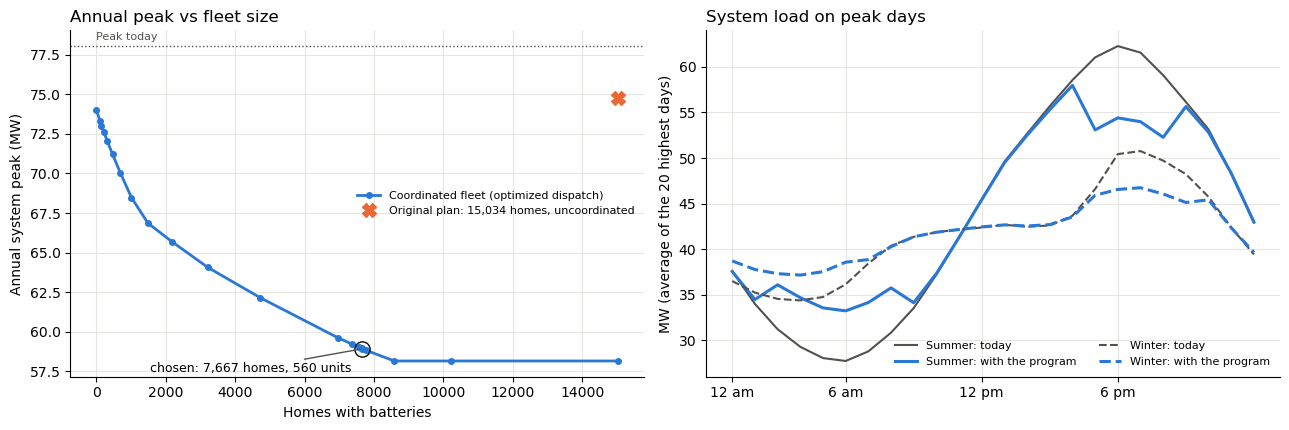

Annual peak: 78.049 MW today, 74.784 MW with the original plan, 73.319 MW with the 293 homes that clear the NPV threshold (the knee fleet's optimizer estimate: 58.923 MW)


In [6]:
import matplotlib.pyplot as plt

s = json.loads((PART3 / 'nyseg' / 'app_data.json').read_text())['summary']
f = s['fleet']
cv = pl.DataFrame(f['curve'])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
a1.plot(cv['homes'], cv['peak_mw'], color='#2a78d6', linewidth=2, marker='o', markersize=4,
        label='Coordinated fleet (optimized dispatch)')
a1.plot(f['selected_homes'], f['lp_peak_mw'], marker='o', markersize=11, markerfacecolor='none', markeredgecolor='#0b0b0b')
a1.annotate(f"chosen: {f['selected_homes']:,} homes, {f['selected_units']:,} units",
            xy=(f['selected_homes'], f['lp_peak_mw']), xytext=(f['selected_homes'] * 0.2, f['lp_peak_mw'] - 1.5),
            arrowprops=dict(arrowstyle='-', color='#52514e'), fontsize=9)
u = f['uncoordinated']
a1.plot(u['homes'], u['peak_mw_after'], marker='X', markersize=10, color='#eb6834', linestyle='none',
        label=f"Original plan: {u['homes']:,} homes, uncoordinated")
a1.axhline(s['system_peak_mw_before'], color='#52514e', linewidth=1, linestyle=':')
a1.text(0, s['system_peak_mw_before'] + 0.4, 'Peak today', fontsize=8, color='#52514e')
a1.set_xlabel('Homes with batteries')
a1.set_ylabel('Annual system peak (MW)')
a1.set_title('Annual peak vs fleet size', loc='left')
a1.legend(frameon=False, loc='center right', fontsize=8)
hours = list(range(1, 25))
for season, ls in (('summer', '-'), ('winter', '--')):
    prof = s['system_profile_mw'][season]
    a2.plot(hours, prof['before'], color='#52514e', linestyle=ls, linewidth=1.5, label=f'{season.title()}: today')
    a2.plot(hours, prof['after'], color='#2a78d6', linestyle=ls, linewidth=2.2, label=f'{season.title()}: with the program')
a2.set_xticks([1, 6, 12, 18], ['12 am', '6 am', '12 pm', '6 pm'])
a2.set_ylabel('MW (average of the 20 highest days)')
a2.set_title('System load on peak days', loc='left')
a2.legend(frameon=False, fontsize=8, ncol=2, loc='lower right')
for ax in (a1, a2):
    ax.grid(color='#e6e5e1')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(config.EDA_DIR / 'planner_fleet_curve.png', dpi=150)
plt.show()
print(f"Annual peak: {s['system_peak_mw_before']} MW today, {u['peak_mw_after']} MW with the original plan, "
      f"{f['peak_mw_after']} MW with the {f.get('program_homes', f['selected_homes']):,} homes that clear the NPV threshold "
      f"(the knee fleet's optimizer estimate: {f['lp_peak_mw']} MW)")

### Which candidates make the knee fleet

The knee fleet is set by the ranking and the knee, not by a threshold, but the ranking measure implies one: a candidate
joins it only if its batteries can cover at least the cutoff below at the system-peak hour (averaged over the 60 highest
days). Battery dispatch doesn't use prices, so the fleet and cutoff are the same for every utility. `selected_homes` is
the knee fleet and `program_homes` the homes that also clear the NPV threshold (section 3b); the table by group splits
all candidates into the program's homes ("selected") and the rest.

Two-unit homes in the fleet cover less per unit than one-unit homes, because the step-1 rule for a second unit (it adds
at least 0.5 kW) is far below a unit's 3.84 kW rating. Letting the optimization choose each home's number of units, not
just whether it joins, would probably reach the same peak with fewer units.

In [7]:
fleets = pl.DataFrame([{'utility': u, **{k: f.get(k) for k in ('candidates', 'selected_homes', 'program_homes',
                                                                'selected_units', 'cutoff_kw', 'peak_mw_after')}}
                       for u in UTILITIES
                       for f in [json.loads((PART3 / u / 'app_data.json').read_text())['summary']['fleet']]])
groups = pl.DataFrame(s['fleet']['cover_by_group']).with_columns((pl.col('median_kw') / pl.col('units')).alias('median_kw_per_unit'))
with pl.Config(tbl_width_chars=200, tbl_hide_dataframe_shape=True, float_precision=2):
    print(fleets)
    print(f"\nCutoff: a candidate's batteries must cover at least {s['fleet']['cutoff_kw']:.2f} kW at the system-peak hour. "
          'kW covered at the peak hour, by group:')
    print(groups)

┌─────────┬────────────┬────────────────┬───────────────┬────────────────┬───────────┬───────────────┐
│ utility ┆ candidates ┆ selected_homes ┆ program_homes ┆ selected_units ┆ cutoff_kw ┆ peak_mw_after │
│ ---     ┆ ---        ┆ ---            ┆ ---           ┆ ---            ┆ ---       ┆ ---           │
│ str     ┆ i64        ┆ i64            ┆ i64           ┆ i64            ┆ f64       ┆ f64           │
╞═════════╪════════════╪════════════════╪═══════════════╪════════════════╪═══════════╪═══════════════╡
│ nyseg   ┆ 15034      ┆ 7667           ┆ 293           ┆ 560            ┆ 2.07      ┆ 73.32         │
│ cmp     ┆ 15034      ┆ 7667           ┆ 293           ┆ 560            ┆ 2.07      ┆ 73.32         │
│ rge     ┆ 15034      ┆ 7667           ┆ 293           ┆ 560            ┆ 2.07      ┆ 73.32         │
│ ui      ┆ 15034      ┆ 7667           ┆ 293           ┆ 560            ┆ 2.07      ┆ 73.32         │
└─────────┴────────────┴────────────────┴───────────────┴────────────────

### 3b. The battery candidate threshold that maximizes project NPV

A home is a battery candidate only if one unit cuts its peak-hour load by at least a threshold in the per-home
simulation. Rather than fix it, the build chooses it for **project NPV**: the present value of the avoided capacity
value of the expected peak reduction, less the upfront investment.

- For a threshold $\tau$, the candidates are the knee fleet's homes $i$ with one-unit reduction $g_i \ge \tau$.
- Each counts at its group's acceptance rate $p_i$: 40% for likely adopters (year-1 savings, bill savings plus the
  performance incentive, above $100) and 20% for the rest.
- Its contribution is $p_i\,(y_i\,V\,PV - K_i)$, where $y_i$ is its battery's reduction at the system peak hours (kW, from
  the fleet dispatch), $V$ the avoided capacity value (\$/kW-yr), $PV$ the present value of \$1 a year over the battery
  life at the discount rate with degradation, and $K_i$ its hardware + installation cost.
- Flexibility adds the same value at every threshold: 50% enrollment × its peak relief × $V$ × $PV$.

$$\text{NPV}(\tau) = F + \sum_{i:\,g_i \ge \tau} p_i\,(y_i\,V\,PV - K_i)$$

The build uses the $\tau$ (at least 0.5 kW) that maximizes NPV. If none makes batteries pay, NPV is highest with no
batteries, and it uses instead the **lowest threshold at which NPV is still at least zero**: the largest battery program
that flexibility's value can pay for. It then rebuilds the fleet with only the homes that clear it, so the planner's
peak-day chart, annual peak and Customer List match (`npv_threshold` and `main()` in `scripts/run_part3.py`). The page
repeats the same calculation whenever an Assumptions or Scenario Analysis input is applied.

The performance incentive is a transfer to the customer and isn't counted. NPV counts only battery hardware,
installation and avoided capacity value, not other things Avangrid may value such as grid flexibility or lower carbon
emissions.

┌─────────┬───────┬───────────┬───────┬────────────┬─────────┐
│ utility ┆ tau   ┆ rule      ┆ npv   ┆ candidates ┆ flex_mw │
│ ---     ┆ ---   ┆ ---       ┆ ---   ┆ ---        ┆ ---     │
│ str     ┆ f64   ┆ str       ┆ i64   ┆ i64        ┆ f64     │
╞═════════╪═══════╪═══════════╪═══════╪════════════╪═════════╡
│ nyseg   ┆ 1.315 ┆ breakeven ┆ 21864 ┆ 293        ┆ 4.652   │
│ cmp     ┆ 1.315 ┆ breakeven ┆ 3069  ┆ 293        ┆ 4.652   │
│ rge     ┆ 1.315 ┆ breakeven ┆ 18134 ┆ 293        ┆ 4.652   │
│ ui      ┆ 1.315 ┆ breakeven ┆ 10637 ┆ 293        ┆ 4.652   │
└─────────┴───────┴───────────┴───────┴────────────┴─────────┘


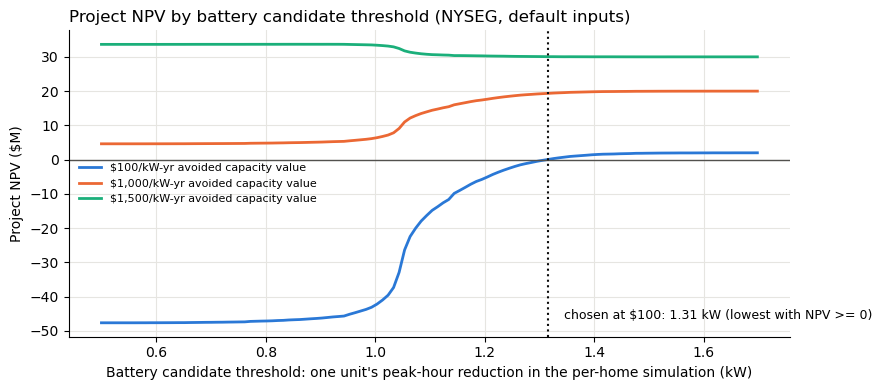

At $100/kW-yr no candidate's battery pays; the first one does above about $1,067/kW-yr. Chosen threshold: 1.315 kW, 293 candidates, NPV $21,864.


/var/folders/5n/4_9dvwrx6hq5td0gdc7d67d80000gn/T/ipykernel_73792/95777279.py:35: RuntimeWarning: divide by zero encountered in divide
  be = (cost / (np.maximum(pts[:, 4], 0) * pvf)).min()


In [8]:
cfg0 = json.loads((ROOT / 'config' / 'part3_assumptions.json').read_text())
sel = pl.DataFrame([{'utility': u, **json.loads((PART3 / u / 'app_data.json').read_text())['summary']['npv_threshold']}
                    for u in UTILITIES])
with pl.Config(tbl_width_chars=200, tbl_hide_dataframe_shape=True, float_precision=3):
    print(sel)

sm = json.loads((PART3 / 'nyseg' / 'app_data.json').read_text())['summary']
pts = np.array([p_[:6] for p_ in sm['battery_points']['points']])
ad, fn, ck = cfg0['adoption'], cfg0['finance'], sm['battery_points']['candidate_kw']
pvf = sum((1 - fn['degradation']) ** y / (1 + fn['discount_rate']) ** (y + 1) for y in range(fn['life_years']))
cost = pts[:, 2] * fn['battery_capex_per_unit'] + fn['install_base'] + (pts[:, 2] - 1) * fn['install_per_extra_unit']
prob = np.where(pts[:, 0] > ad['likely_threshold'], ad['likely_rate'], ad['less_likely_rate'])
taus = np.linspace(ck, pts[:, 5].max() + 0.01, 120)
fig, ax = plt.subplots(figsize=(9, 4))
for V, col in ((cfg0['economics']['avoided_capacity_per_kw_yr'], '#2a78d6'), (1000, '#eb6834'), (1500, '#1baf7a')):
    c_i = prob * (np.maximum(pts[:, 4], 0) * V * pvf - cost)
    F = ad['flex_share'] * sm['npv_threshold']['flex_mw'] * 1e3 * V * pvf
    npv = np.array([F + c_i[(pts[:, 5] >= t) & (pts[:, 5] >= ck)].sum() for t in taus]) / 1e6
    ax.plot(taus, npv, color=col, linewidth=2, label=f'${V:,}/kW-yr avoided capacity value')
ax.axhline(0, color='#52514e', linewidth=1)
nt = sm['npv_threshold']
ax.axvline(nt['tau'], color='#0b0b0b', linestyle=':', linewidth=1.5)
ax.text(nt['tau'] + 0.03, ax.get_ylim()[0] * 0.9, f"chosen at ${cfg0['economics']['avoided_capacity_per_kw_yr']}: "
        f"{nt['tau']:.2f} kW ({'max NPV' if nt['rule'] == 'max' else 'lowest with NPV >= 0'})", fontsize=9)
ax.set_xlabel("Battery candidate threshold: one unit's peak-hour reduction in the per-home simulation (kW)")
ax.set_ylabel('Project NPV ($M)')
ax.set_title('Project NPV by battery candidate threshold (NYSEG, default inputs)', loc='left')
ax.legend(frameon=False, fontsize=8)
ax.grid(color='#e6e5e1')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(config.EDA_DIR / 'planner_npv_threshold.png', dpi=150)
plt.show()
be = (cost / (np.maximum(pts[:, 4], 0) * pvf)).min()
print(f"At ${cfg0['economics']['avoided_capacity_per_kw_yr']}/kW-yr no candidate's battery pays; the first one does above "
      f"about ${be:,.0f}/kW-yr. Chosen threshold: {nt['tau']:.3f} kW, {nt['candidates']:,} candidates, NPV ${nt['npv']:,.0f}.")

## 4. The starting page, with a utility drop-down

`onedrive-export/Data/part3/index.html` shows one utility's planner at a time and switches with the drop-down
(the choice is kept in the address, e.g. `index.html#ui`). Each utility's page can also be opened on its own.
Everything is local files: no internet connection or server is needed.

In [9]:
options = '\n'.join(f'<option value="{u}">{label}</option>' for u, label in UTILITIES.items())
chooser = f"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Demand flexibility and battery planner by utility</title>
<style>
  :root {{ color-scheme: light dark; }}
  body {{ margin: 0; font: 14px/1.4 system-ui, sans-serif; display: flex; flex-direction: column; height: 100vh; }}
  header {{ display: flex; gap: 12px; align-items: center; flex-wrap: wrap; padding: 8px 16px;
            border-bottom: 1px solid #8884; }}
  select {{ font: inherit; padding: 4px 8px; }}
  .note {{ color: #888; font-size: 12px; }}
  iframe {{ flex: 1; border: 0; width: 100%; }}
</style></head>
<body>
<header>
  <label for="u"><b>Utility rate</b></label>
  <select id="u">{options}</select>
  <a id="open" target="_blank">Open on its own</a>
  <span class="note">Same homes and batteries; savings, payback and ranking priced on each utility's residential
  time-varying rate. Real customer data: do not share outside the event.</span>
</header>
<iframe id="f" title="Planner"></iframe>
<script>
  const sel = document.getElementById('u'), frame = document.getElementById('f'), open = document.getElementById('open');
  function show(u) {{ sel.value = u; frame.src = u + '/index.html'; open.href = u + '/index.html'; location.hash = u; }}
  sel.addEventListener('change', () => show(sel.value));
  const start = location.hash.slice(1);
  show([...sel.options].some(o => o.value === start) ? start : sel.options[0].value);
</script>
</body></html>
"""
(PART3 / 'index.html').write_text(chooser)
for utility in UTILITIES:
    page = PART3 / utility / 'index.html'
    print(f'{utility}: {page.stat().st_size / 1e6:.1f} MB')
top = pl.read_csv(PART3 / 'nyseg' / 'candidates.csv')
print(f'\nTop of the ranking on NYSEG\'s Day/Night rate ({top.height:,} customers ranked):')
with pl.Config(tbl_cols=12, tbl_width_chars=200, tbl_hide_dataframe_shape=True):
    print(top.head(10))
page = PART3 / 'index.html'
display(Markdown(f'**Open the planner:** [{page}]({page.resolve().as_uri()})'))

nyseg: 10.4 MB
cmp: 10.4 MB
rge: 10.4 MB
ui: 10.4 MB

Top of the ranking on NYSEG's Day/Night rate (33,310 customers ranked):
┌──────┬──────────┬─────────────────────────────────┬────────────────┬───────┬────────┬───┬─────────────┬───────────────┬──────┬────────┬─────────┬─────────────────────────────────┐
│ rank ┆ customer ┆ segment                         ┆ action         ┆ units ┆ wave   ┆ … ┆ p_heat_pump ┆ p_resist_heat ┆ p_ac ┆ p_pool ┆ p_solar ┆ reason                          │
│ ---  ┆ ---      ┆ ---                             ┆ ---            ┆ ---   ┆ ---    ┆   ┆ ---         ┆ ---           ┆ ---  ┆ ---    ┆ ---     ┆ ---                             │
│ i64  ┆ i64      ┆ str                             ┆ str            ┆ i64   ┆ str    ┆   ┆ f64         ┆ f64           ┆ f64  ┆ f64    ┆ f64     ┆ str                             │
╞══════╪══════════╪═════════════════════════════════╪════════════════╪═══════╪════════╪═══╪═════════════╪═══════════════╪══════╪════════╪═════════

**Open the planner:** [/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/part3/index.html](file:///Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/part3/index.html)

## Tried but not used

| Tried | Why it isn't used |
|---|---|
| **Per-home battery dispatch** (the planner's original method: each battery shaves its own home's load in a fixed 4-hour window and recharges in the same 6 overnight hours) | Every battery charging at once created a new overnight peak, above today's peak on winter peak days, and offering a battery to every candidate home (15,034) cut the annual peak by only 3.3 MW. The coordinated fleet reaches a far lower peak with about half the homes. The per-home simulation is still used to choose candidates and sizes. |
| **A live web app reading the database** (the earlier battery simulator: a FastAPI server, `app/server.py`, and its page, `web/index.html`, plus a Streamlit prototype) | Removed in favour of the planner. A page with its data built in needs no server, port or running database, so judges only need a browser, and it can be opened on a machine without the data. The trade-off: changing an assumption in `config/part3_assumptions.json` means re-running this notebook. |